In [1]:
import os
import torch
from GAN.src.model import build_res_unet, MainModel
from CNN.src.model import build_colorization_model
from src.evaluate import evaluate_all
from src.visualize import visualize
from GAN.src.get_gan_checkpoints import get_gan_checkpoints

2025-04-04 01:05:05.663960: I tensorflow/core/platform/cpu_feature_guard.cc:182] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


In [2]:
# disable tensorflow progress bars and skimage UserWarnings
os.environ['TF_CPP_MIN_LOG_LEVEL'] = "2"
import warnings
warnings.filterwarnings("ignore", category=UserWarning)

In [3]:
get_gan_checkpoints()

ResNet backbone already available
base model already available
finetuned model already available


In [4]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Load models

In [5]:
# CNN
# Define image size
img_size = 256

# Create the model
cnn = build_colorization_model(input_shape=(img_size, img_size, 1))

# Load weights from the .h5 file
cnn.load_weights("CNN/checkpoints/colorization-faces-unet-0.009.h5")

In [6]:
# cGANs
# load generators
net_G1 = build_res_unet(n_input=1, n_output=2, size=256)
net_G1.load_state_dict(torch.load("GAN/checkpoints/res18-unet.pt", map_location=device))

net_G2 = build_res_unet(n_input=1, n_output=2, size=256)
net_G2.load_state_dict(torch.load("GAN/checkpoints/res18-unet.pt", map_location=device))

<All keys matched successfully>

In [7]:
# base model
gan1 = MainModel(net_G = net_G1)
gan1.load_state_dict(torch.load("GAN/checkpoints/final_model_weights.pt", map_location=device))

model initialized with norm initialization


<All keys matched successfully>

In [8]:
# finetuned model
gan2 = MainModel(net_G = net_G2)
gan2.load_state_dict(torch.load("GAN/checkpoints/fine_tuned_faces.pt", map_location=device))

model initialized with norm initialization


<All keys matched successfully>

# Visualizations

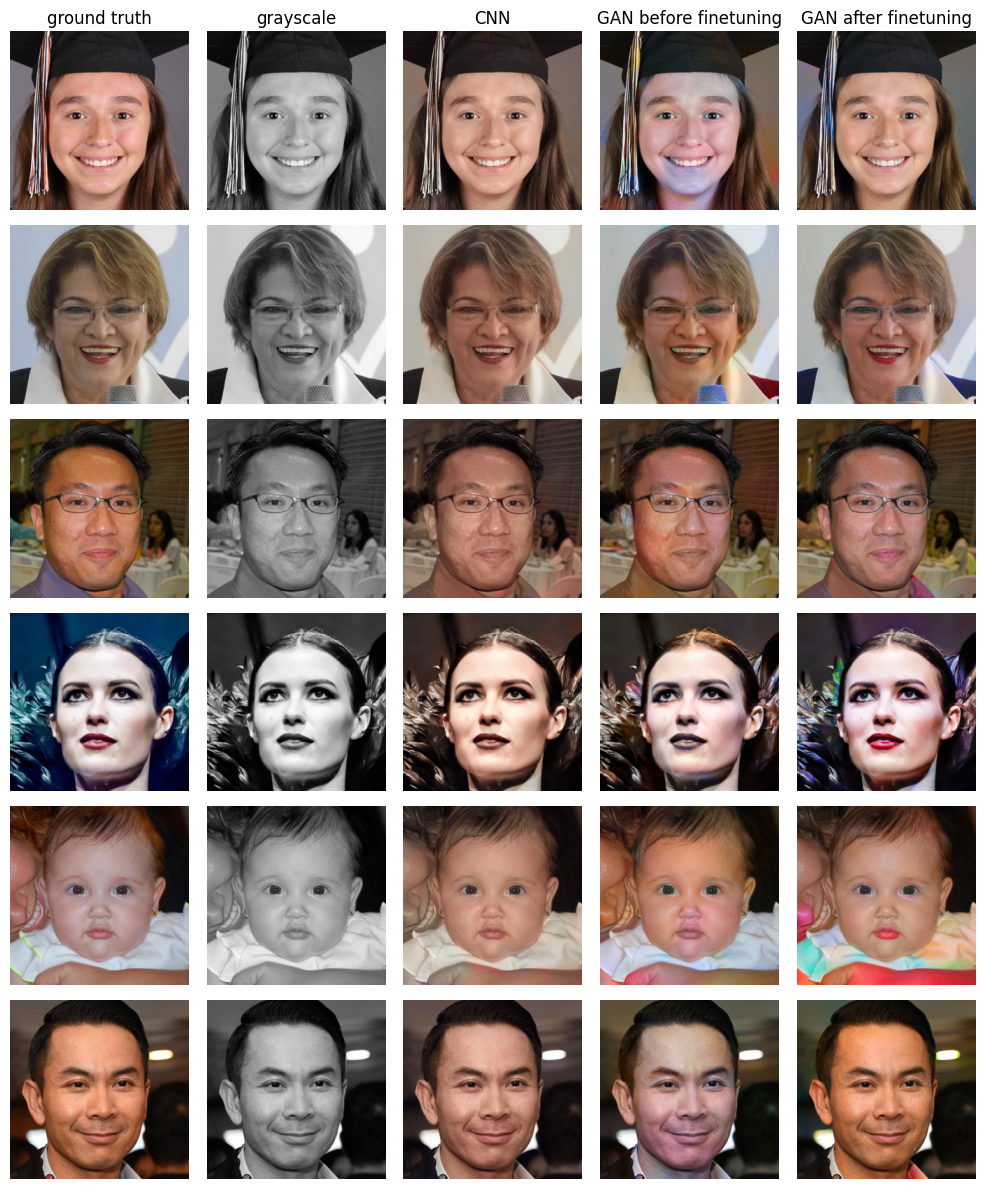

In [9]:
visualize(cnn,gan1,gan2,"data/faces_val", seed = 1, num_images = 6)

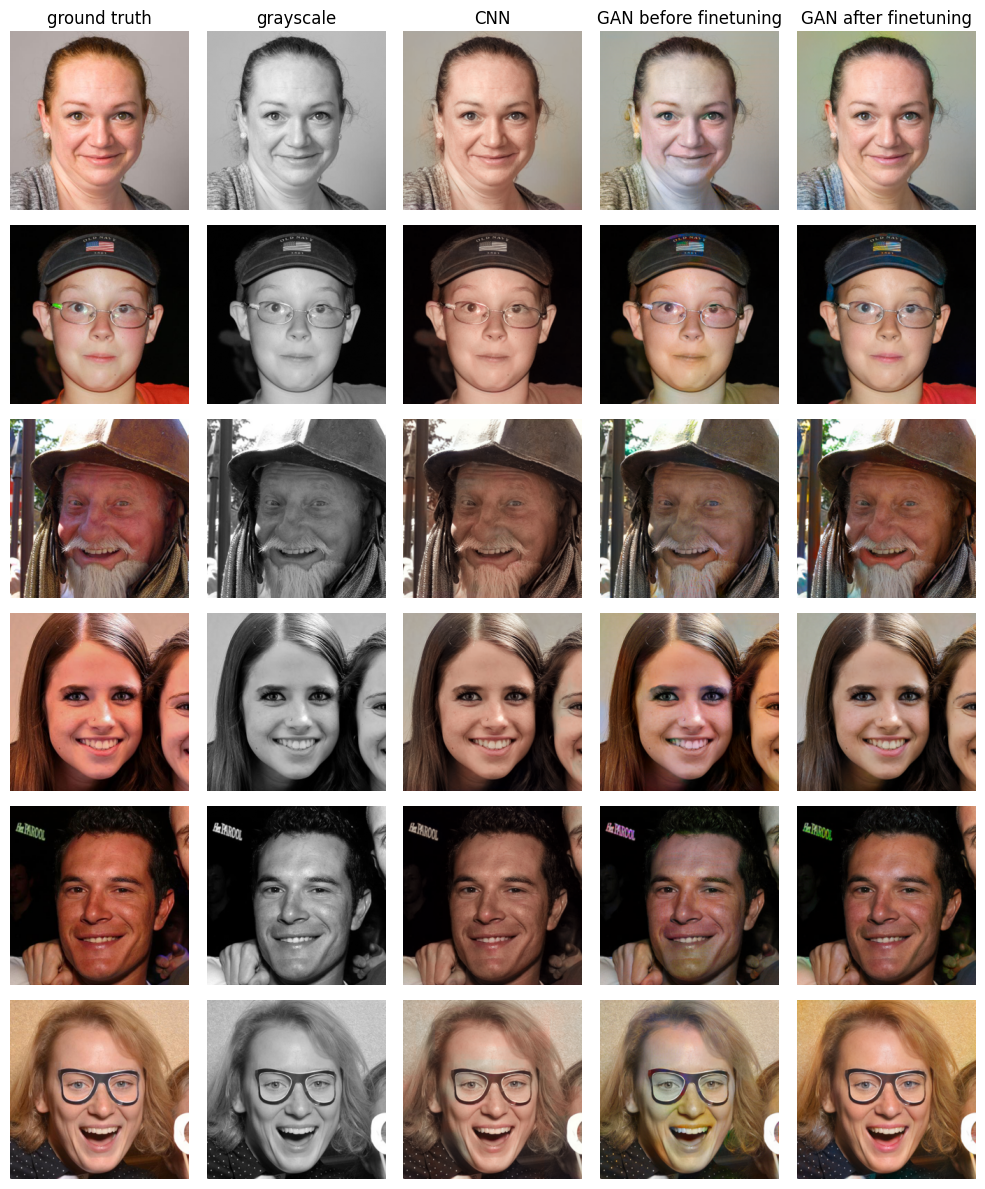

In [10]:
visualize(cnn,gan1,gan2,"data/faces_val", seed = 55, num_images = 6)

# Evaluation

In [12]:
# number of images to be evaluated
val_path = "data/faces_val"
num_images = 100
seed = 13

In [15]:
eval = evaluate_all(cnn, gan1, gan2, val_path=val_path, seed=seed, size=num_images)

  0%|          | 0/100 [00:00<?, ?it/s]

In [16]:
print(eval)

+---------------------+--------+----------+---------------+
|        metric       |  CNN   | base GAN | finetuned GAN |
+---------------------+--------+----------+---------------+
|  CIEDE 2000 Delta E | 8.461  |  10.003  |     8.145     |
| mean average chroma | 40.51  |  41.459  |     43.659    |
|         MSE         | 56.504 |  62.221  |     53.054    |
+---------------------+--------+----------+---------------+
